# Gradient Boosting results (same structure as `results_rf.ipynb`)


## Setup

Same split, features and `experiment_results` table as the RF notebook.

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
from common import get_client

## Default model


In [7]:
df = get_client().query_df(
    "SELECT Model_Name,Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Model_Name = 'gb_delay_y1_f25_default'"
)

df

,Model_Name,Train_Rows,val_lift,train_lift
0,gb_delay_y1_f25_default,1728215,1.712923,1.993793


## Learning curve


In [27]:
df = get_client().query_df(
    "SELECT Model_Name, Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Model_Name IN ('gb_delay_y1_f12.5_curve_default', 'gb_delay_y1_f25_curve_default', 'gb_delay_y1_f50_curve_default', 'gb_delay_y1_f100_curve_default')"
)

df = df.sort_values("val_lift")
df

,Model_Name,Train_Rows,val_lift,train_lift
1,gb_delay_y1_f12.5_curve_default,864107,1.703661,2.038661
2,gb_delay_y1_f25_curve_default,1728215,1.712274,1.992504
3,gb_delay_y1_f50_curve_default,3456430,1.717912,1.968889
0,gb_delay_y1_f100_curve_default,6912859,1.720752,1.952362


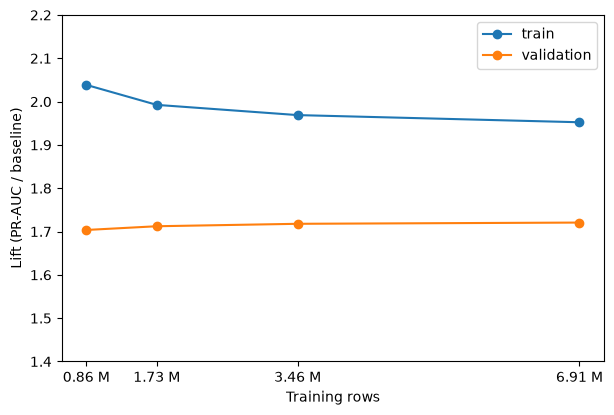

In [38]:
models = ["GB Fraction_12.5","GB Fraction_25", "GB Fraction_50", "GB Fraction_100"]

fig , ax = plt.subplots(figsize=(7, 4.5))

ax.plot(df["Train_Rows"], df["train_lift"], marker="o", label="train")
ax.plot(df["Train_Rows"], df["val_lift"], marker="o", label="validation")
ax.set_ylim(1.4,2.2)

ax.set_xticks(df["Train_Rows"])
ax.set_xticklabels([f"{r / 1e6:.2f} M" for r in df["Train_Rows"]])
ax.set_xlabel("Training rows")
ax.set_ylabel("Lift (PR-AUC / baseline)")


ax.legend()




In [35]:
fig.savefig("../docs/figures/learning_curve_gb_default.png", dpi=150, bbox_inches="tight")

## Hyperparameter tuning


## Default vs final comparison
